# 8.4. Phân tích kết quả nhận dạng ký tự trên các tình huống thực tế (ALPR OCR Case Studies)

Notebook này trực quan hóa và đối chứng thực nghiệm cho **Mục 8.4** của báo cáo dự án ALPR Việt Nam.
Dữ liệu và bằng chứng được trích xuất trực tiếp từ các thư mục thực nghiệm trong dự án:
- `experiments/compare-alpr-A-B/`: Bộ đối chứng hai ảnh điển hình A và B.
- `experiments/targeted-ocr-fix/`: Bản vá lỗi phân tách 2 dòng và chuẩn hóa formatter.
- `experiments/ocr-recognition-study/`: Nghiên cứu nhận dạng ký tự EasyOCR trên các crop cố định.
- `assets/samples/`: Ảnh mẫu kiểm thử runtime API.

In [1]:
import os
import cv2
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Thiết lập đường dẫn gốc dự án
PROJECT_ROOT = Path("../..").resolve()
ADD_ROOT = Path("..").resolve()
print(f"Project root: {PROJECT_ROOT}")

def show_images(images, titles, figsize=(16, 6), cmap=None):
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=figsize)
    if n == 1:
        axes = [axes]
    for ax, img, title in zip(axes, images, titles):
        if len(img.shape) == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap=cmap or 'gray')
        ax.set_title(title, fontsize=12, pad=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

Project root: D:\HOC_TAP\Bao_cao\CCNLTHD


--- 
## 1. Cặp ảnh đối chứng A và B (Baseline ALPR Pipeline)

- **Ảnh A (`img_0167`):** Xe máy, góc chụp nghiêng (~26°), kích thước lớn (3072×4096), dính bảng quảng cáo nền. Gặp lỗi đa tầng (Detection false positive, CRAFT áp lực bộ nhớ, Lỗi grouping ghép xoắn 2 hàng).
- **Ảnh B (`img_0197`):** Xe máy, góc chụp trực diện chuẩn, nhận diện thành công hoàn hảo từ Detection đến Final OCR.

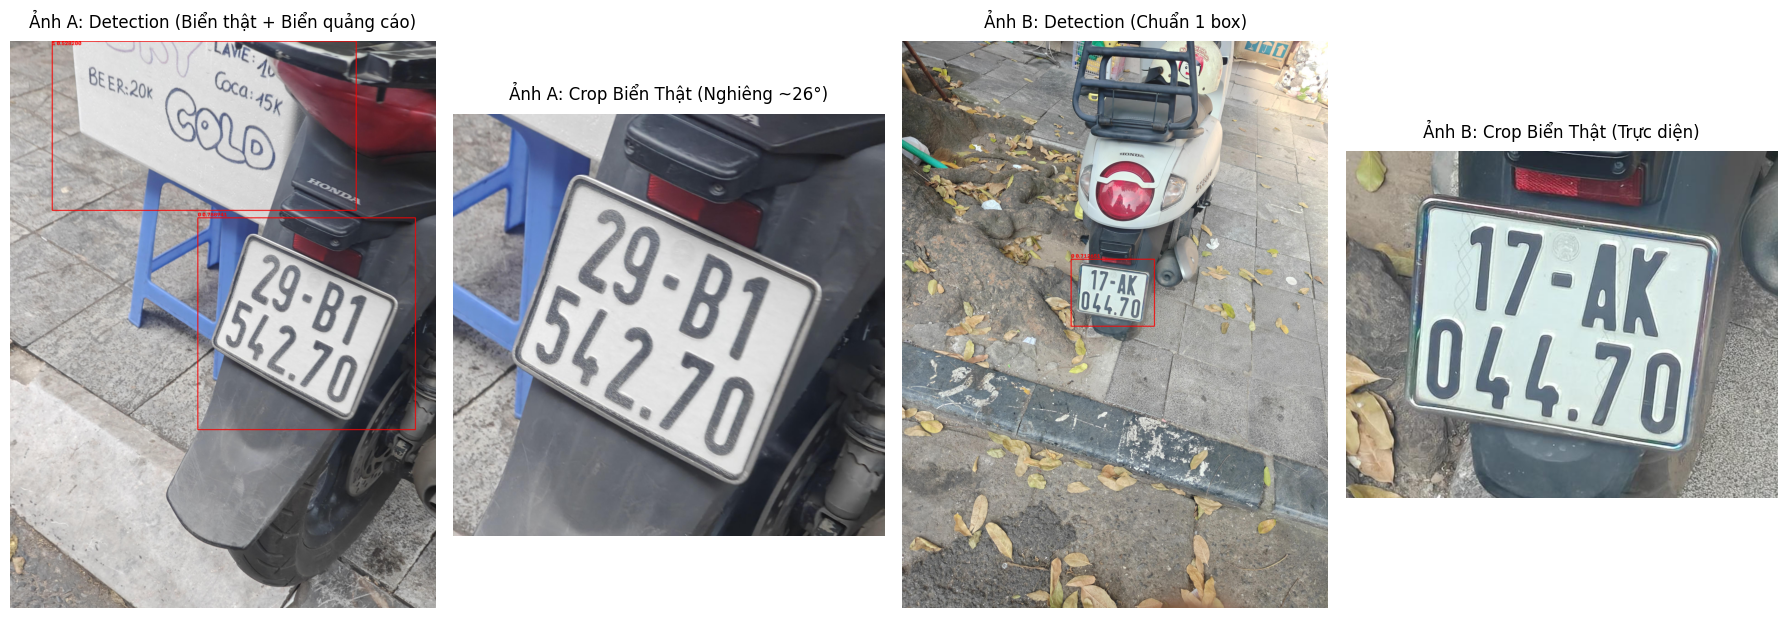

In [2]:
# Load ảnh và overlays đối chứng A và B
exp_ab = PROJECT_ROOT / "experiments" / "compare-alpr-A-B"

img_a_det = cv2.imread(str(exp_ab / "A-lazy" / "detections.jpg"))
img_b_det = cv2.imread(str(exp_ab / "B-lazy" / "detections.jpg"))

crop_a = cv2.imread(str(exp_ab / "A-lazy" / "det-0" / "00-crop.png"))
crop_b = cv2.imread(str(exp_ab / "B-lazy" / "det-0" / "00-crop.png"))

show_images(
    [img_a_det, crop_a, img_b_det, crop_b],
    ["Ảnh A: Detection (Biển thật + Biển quảng cáo)", "Ảnh A: Crop Biển Thật (Nghiêng ~26°)", 
     "Ảnh B: Detection (Chuẩn 1 box)", "Ảnh B: Crop Biển Thật (Trực diện)"],
    figsize=(18, 6)
)

### Bounding box CRAFT và Lỗi gom hàng (Line Grouping) trên Ảnh A vs Ảnh B
- **Ảnh B:** CRAFT phát hiện 2 box ngang độc lập `['17-AK']` (conf 0.906) và `['044.70']` (conf 0.999). Grouping 2 hàng chính xác -> Final: `17AK-044.70`.
- **Ảnh A:** CRAFT bắt trọn 2 hàng nhưng dính thêm ký tự viền nền `C` (conf 0.010). Do góc nghiêng lớn, thuật toán gom hàng cũ dùng chênh lệch center-Y bị nhập 2 dòng làm một, sort theo X tạo thành chuỗi xoắn: `542.29-B170` -> Formatter từ chối (`format_status: unrecognized`).

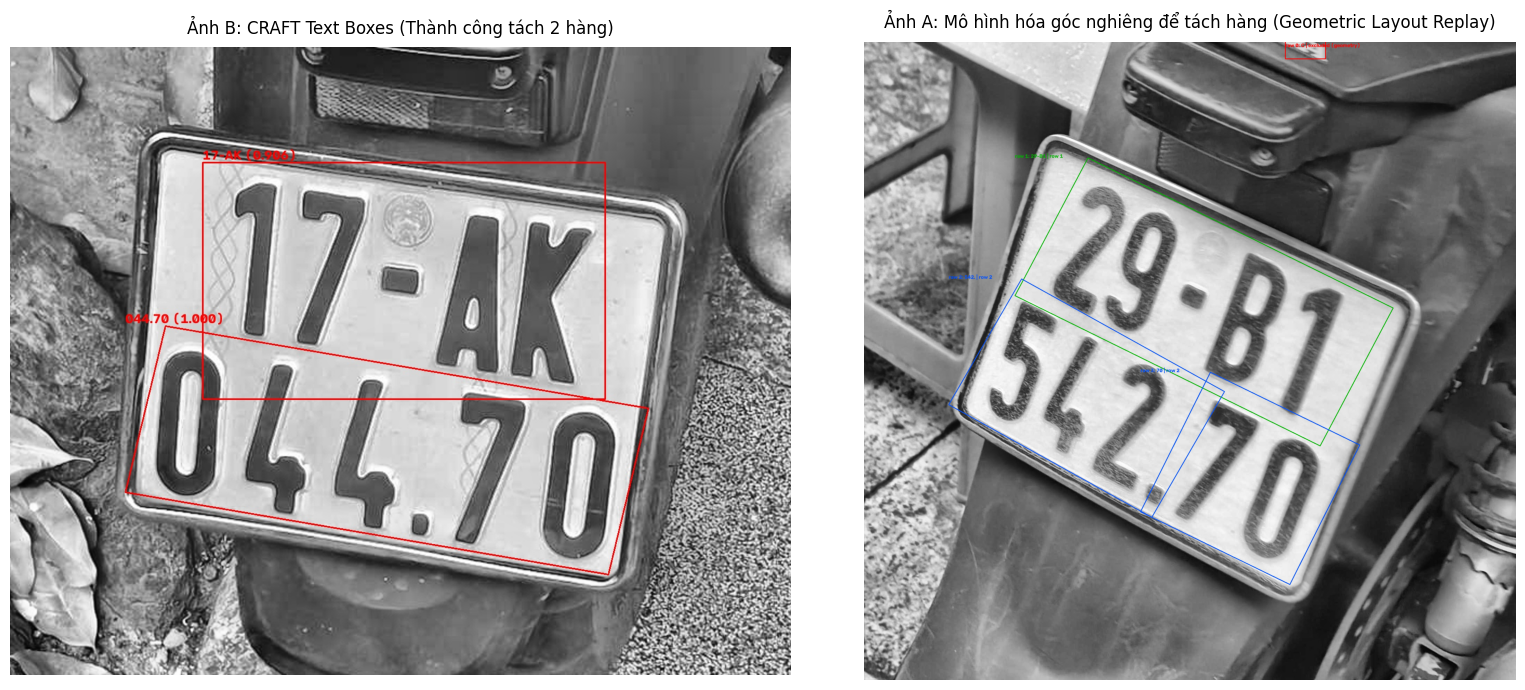

In [3]:
ocr_boxes_b = cv2.imread(str(exp_ab / "B-lazy" / "det-0" / "ocr-0-boxes.jpg"))
layout_a = cv2.imread(str(PROJECT_ROOT / "experiments" / "plate-A-recognition-fix" / "A-offline-layout-overlay.jpg"))

show_images(
    [ocr_boxes_b, layout_a],
    ["Ảnh B: CRAFT Text Boxes (Thành công tách 2 hàng)",
     "Ảnh A: Mô hình hóa góc nghiêng để tách hàng (Geometric Layout Replay)"],
    figsize=(16, 7)
)

--- 
## 2. Điển hình lỗi lệch Bounding Box YOLO và Formatter Heuristic (`assets/samples/1.jpg`)

- **Ground Truth:** Biển số Kiên Giang 2 dòng `68-G1 668.86`.
- **Thực tế Detection:** Bbox YOLO bị cắt thiếu biên phải và biên dưới, chỉ đạt confidence `0.2942`.
- **Hậu quả OCR:** Hàng trên nhận `68-61` (conf 0.495), hàng dưới nhận `G6Q` (conf 0.244). Bị mất hoàn toàn 2 số cuối `.86`.
- **Hành vi Formatter cũ vs mới:** 
  + Formatter cũ: Ép chữ tùy tiện `68-61` -> `68-G1`, `G6Q` -> `660` -> Trả về kết quả sai lệch `68-G1 660`.
  + Formatter sau bản vá targeted-fix: Kiểm tra tính đầy đủ của biển số xe máy 5 số -> Nhận thấy không đủ ký tự hợp lệ -> Trả về chuỗi rỗng an toàn (`format_status: unrecognized`).

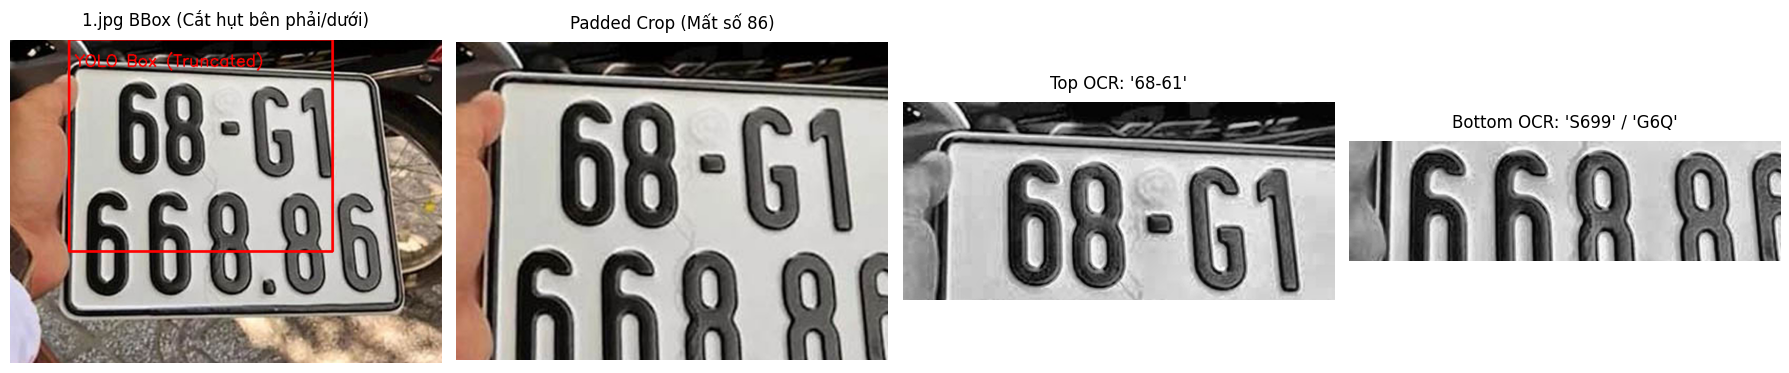

In [4]:
sample1_path = PROJECT_ROOT / "assets" / "samples" / "1.jpg"
img_sample1 = cv2.imread(str(sample1_path))

# Bbox thực tế từ quá trình audit:
# xyxy = [109.1, 0.0, 597.4, 392.8] trên ảnh 800x600
h, w, _ = img_sample1.shape
cv2.rectangle(img_sample1, (109, 0), (597, 393), (0, 0, 255), 3)
cv2.putText(img_sample1, "YOLO Box (Truncated)", (120, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 2)

# Crop có padding 10%
crop_sample1 = cv2.imread(str(PROJECT_ROOT / "experiments" / "ocr-recognition-study" / "cases" / "sample-1" / "inputs" / "raw_whole-whole.png"))
top_sample1 = cv2.imread(str(PROJECT_ROOT / "experiments" / "ocr-recognition-study" / "cases" / "sample-1" / "inputs" / "current_split-top.png"))
bottom_sample1 = cv2.imread(str(PROJECT_ROOT / "experiments" / "ocr-recognition-study" / "cases" / "sample-1" / "inputs" / "current_split-bottom.png"))

show_images(
    [img_sample1, crop_sample1, top_sample1, bottom_sample1],
    ["1.jpg BBox (Cắt hụt bên phải/dưới)", "Padded Crop (Mất số 86)", "Top OCR: '68-61'", "Bottom OCR: 'S699' / 'G6Q'"],
    figsize=(18, 5)
)

--- 
## 3. Lỗi nhận thêm chữ nền (Background False Positive) (`img_0045` - Case 006-0)

- **Ground Truth:** Biển số xe máy Hà Nội `29-P1 239.64`.
- **Hiện tượng:** Padding và vùng crop của detector dính cả khung xe / dè chắn bùn.
- **Kết quả EasyOCR thô:**
  + `HONDA` (Confidence: **0.974**)
  + `P7` (Confidence: **0.999**)
  + `29-PI` (Confidence: 0.643 - Lỗi đọc nhầm 1 thành I)
  + `239.64` (Confidence: 0.821)
- **Bài học:** Các chữ nền (`HONDA`, `P7`) có độ nét cao nên đạt confidence vượt trội so với chữ biển số thật. Nếu thuật toán chọn text theo confidence cao nhất sẽ bị sai lệch hoàn toàn.

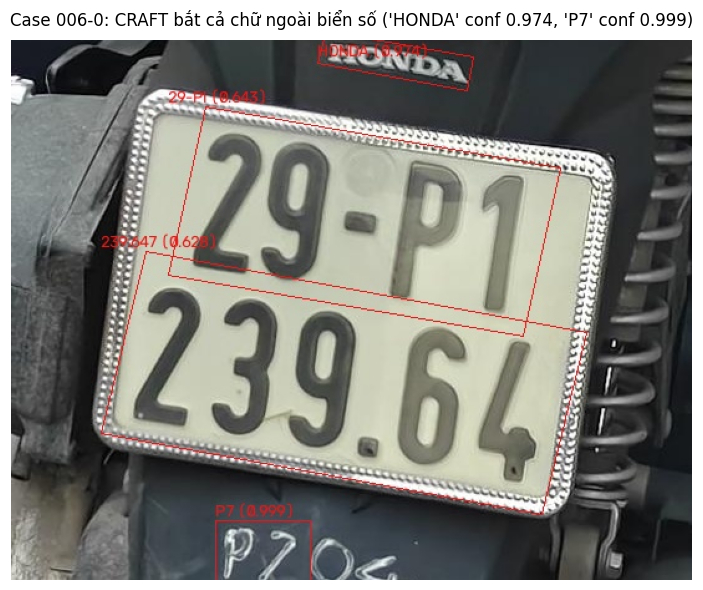

In [5]:
overlay_006 = cv2.imread(str(PROJECT_ROOT / "experiments" / "ocr-recognition-study" / "overlays" / "006-0--raw_whole--whole.jpg"))

show_images(
    [overlay_006],
    ["Case 006-0: CRAFT bắt cả chữ ngoài biển số ('HONDA' conf 0.974, 'P7' conf 0.999)"],
    figsize=(10, 6)
)

--- 
## 4. Lỗi thuật toán phân tách 2 dòng cũ cắt đứt nét chữ (`img_0026` - Case 002-0)

- **Nguyên nhân:** Thuật toán phân đôi 2 dòng cũ tìm cực tiểu hình chiếu ngang (argmin horizontal projection Otsu) trong khoảng 30-70% chiều cao mà không kiểm tra độ rộng khoảng trống (gap).
- **Hậu quả:** Đường cắt rơi vào row 802, cắt ngang qua thân của các chữ số hàng dưới (40.8% foreground ink bị cắt ngang). Khi đưa từng nửa vào CRAFT, hàng trên bị mất hẳn, hàng dưới chỉ còn mảnh vụn `Z3`.
- **Bản vá targeted-fix:** Đưa vào cơ chế `Safe-gap validation`. Nếu không tìm thấy khoảng trống an toàn liên tục không có ink giữa 2 dòng, hệ thống chủ động từ chối split (`rejected_no_reliable_gap`) và chuyển sang nhận dạng toàn crop (Whole-crop fallback).

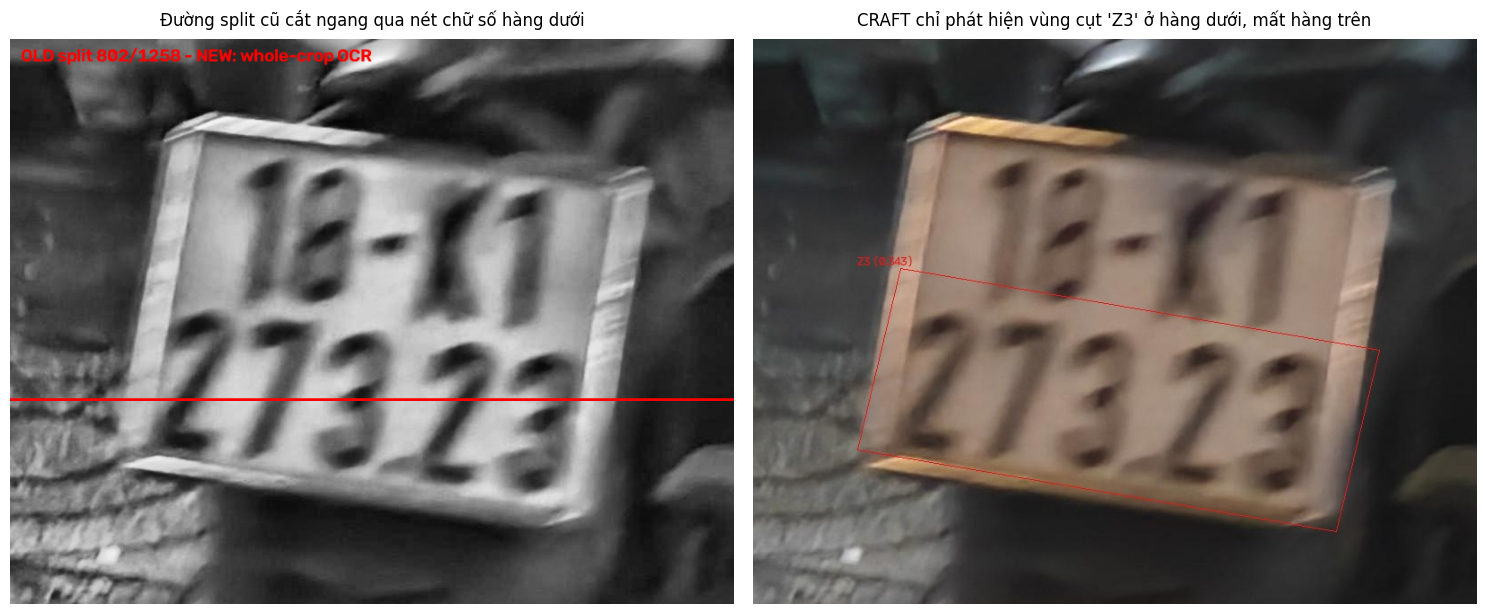

In [6]:
split_review_0026 = cv2.imread(str(PROJECT_ROOT / "experiments" / "targeted-ocr-fix" / "split-0026-review.png"))
overlay_002 = cv2.imread(str(PROJECT_ROOT / "experiments" / "ocr-recognition-study" / "overlays" / "002-0--raw_whole--whole.jpg"))

show_images(
    [split_review_0026, overlay_002],
    ["Đường split cũ cắt ngang qua nét chữ số hàng dưới", "CRAFT chỉ phát hiện vùng cụt 'Z3' ở hàng dưới, mất hàng trên"],
    figsize=(15, 6)
)

--- 
## 5. Tổng hợp Bảng đối chiếu Ground Truth, Raw OCR và Final OCR

Bảng trích xuất trực tiếp từ các file thực nghiệm `experiments/compare-alpr-A-B/raw_ocr.csv`, `experiments/ocr-recognition-study/results.json`, và `experiments/targeted-ocr-fix/before_after.json`.

In [7]:
import pandas as pd

data = [
    {
        "Mã ca": "Ảnh B (img_0197)",
        "Ground Truth": "17-AK 044.70",
        "Raw OCR Fragments (Confidence)": "17-AK [0.906], 044.70 [0.999]",
        "Raw Grouping": "17-AK / 044.70",
        "Final OCR (Cũ)": "17AK-044.70",
        "Final OCR (Mới)": "17AK-044.70",
        "Trạng thái": "Thành công chuẩn mẫu (Structured)"
    },
    {
        "Mã ca": "Ảnh A (img_0167)",
        "Ground Truth": "29-B1 542.70",
        "Raw OCR Fragments (Confidence)": "C [0.011], 29-B1 [0.613], 542. [0.925], 70 [0.999]",
        "Raw Grouping": "C / 542.29-B170 (Ghép xoắn do nghiêng 26°)",
        "Final OCR (Cũ)": "(rỗng - Unrecognized)",
        "Final OCR (Mới)": "29-B1 542.70 (Với layout candidate)",
        "Trạng thái": "Từ chối đúng hoặc định dạng đúng qua layout"
    },
    {
        "Mã ca": "Ảnh C (1.jpg)",
        "Ground Truth": "68-G1 668.86",
        "Raw OCR Fragments (Confidence)": "68-61 [0.495], G6Q [0.244]",
        "Raw Grouping": "68-61 / G6Q",
        "Final OCR (Cũ)": "68-G1 660 (Heuristic ép sai)",
        "Final OCR (Mới)": "(rỗng - Từ chối chuỗi rỗng)",
        "Trạng thái": "Từ chối an toàn do thiếu chữ số"
    },
    {
        "Mã ca": "006-0 (img_0045)",
        "Ground Truth": "29-P1 239.64",
        "Raw OCR Fragments (Confidence)": "HONDA [0.974], P7 [0.999], 29-PI [0.643], 239.64 [0.821]",
        "Raw Grouping": "HONDA / P7 / 29-PI / 239.64",
        "Final OCR (Cũ)": "29PI-239.64 (Nhầm 1 -> I)",
        "Final OCR (Mới)": "29-P1 239.64 (Chuẩn hóa cấu trúc)",
        "Trạng thái": "Lọc chữ nền, sửa series hợp lệ"
    },
    {
        "Mã ca": "024-0 (img_0204)",
        "Ground Truth": "51K-922.52",
        "Raw OCR Fragments (Confidence)": "51K.922.52 [0.845] hoặc 51K-922.52 [0.490]",
        "Raw Grouping": "51K-922.52",
        "Final OCR (Cũ)": "54-K697 021.52 (Lỗi do ép split)",
        "Final OCR (Mới)": "51K-922.52",
        "Trạng thái": "Nhận diện biển 1 dòng chính xác"
    },
    {
        "Mã ca": "052-0 (img_0559)",
        "Ground Truth": "63-B4 189.57",
        "Raw OCR Fragments (Confidence)": "63-84 [0.822], L89.57 [0.624]",
        "Raw Grouping": "63-84 / L89.57",
        "Final OCR (Cũ)": "18P53 (Heuristic đổi tùy tiện L->1, 9->P)",
        "Final OCR (Mới)": "(rỗng - Từ chối chuỗi rỗng)",
        "Trạng thái": "Biển crop quá nhỏ (65x45), từ chối an toàn"
    }
]

df = pd.DataFrame(data)
pd.set_option('display.max_colwidth', None)
df

,Mã ca,Ground Truth,Raw OCR Fragments (Confidence),Raw Grouping,Final OCR (Cũ),Final OCR (Mới),Trạng thái
0,Ảnh B (img_0197),17-AK 044.70,"17-AK [0.906], 044.70 [0.999]",17-AK / 044.70,17AK-044.70,17AK-044.70,Thành công chuẩn mẫu (Structured)
1,Ảnh A (img_0167),29-B1 542.70,"C [0.011], 29-B1 [0.613], 542. [0.925], 70 [0.999]",C / 542.29-B170 (Ghép xoắn do nghiêng 26°),(rỗng - Unrecognized),29-B1 542.70 (Với layout candidate),Từ chối đúng hoặc định dạng đúng qua layout
2,Ảnh C (1.jpg),68-G1 668.86,"68-61 [0.495], G6Q [0.244]",68-61 / G6Q,68-G1 660 (Heuristic ép sai),(rỗng - Từ chối chuỗi rỗng),Từ chối an toàn do thiếu chữ số
3,006-0 (img_0045),29-P1 239.64,"HONDA [0.974], P7 [0.999], 29-PI [0.643], 239.64 [0.821]",HONDA / P7 / 29-PI / 239.64,29PI-239.64 (Nhầm 1 -> I),29-P1 239.64 (Chuẩn hóa cấu trúc),"Lọc chữ nền, sửa series hợp lệ"
4,024-0 (img_0204),51K-922.52,51K.922.52 [0.845] hoặc 51K-922.52 [0.490],51K-922.52,54-K697 021.52 (Lỗi do ép split),51K-922.52,Nhận diện biển 1 dòng chính xác
5,052-0 (img_0559),63-B4 189.57,"63-84 [0.822], L89.57 [0.624]",63-84 / L89.57,"18P53 (Heuristic đổi tùy tiện L->1, 9->P)",(rỗng - Từ chối chuỗi rỗng),"Biển crop quá nhỏ (65x45), từ chối an toàn"


---
## 8.4.0. Quy ước đơn vị đánh giá (Denominator Manifest), Nguồn nhãn Ground Truth & Cơ chế Deskew có điều kiện

Nhằm đảm bảo tính minh bạch và không trộn lẫn mẫu số giữa các đợt đánh giá trong Chương 8:
1. **Bộ kiểm thử Detector (`diagnostic-test`, Mục 8.2):** Gồm **73 ảnh scorable (`103 GT bboxes`)**. Tại ngưỡng vận hành `conf = 0.25, IoU = 0.5`, mô hình sinh ra **117 detections/crops** (`TP = 102, FP = 15, FN = 1`, đạt `Precision = 87.18%`, `Recall = 99.03%`, `AP@0.5 = 0.9880`). Ở thời điểm chạy baseline `diagnostic-test`, bộ 117 crops này chưa có nhãn chuỗi ký tự độc lập (`not_evaluated_no_independent_text_ground_truth`), chỉ ghi nhận 8 crops ra chuỗi Final OCR không rỗng.
2. **Bộ đối soát OCR & E2E (`opt04`/`opt06`, Mục 8.4 – 8.5):** Gồm **N = 17 ảnh đại diện** (đã được xác minh và gán nhãn văn bản Ground Truth thủ công tại `annotations.csv`) cùng các ca chuyên biệt (Ảnh A `img_0167`, Ảnh B `img_0197`, Ảnh C `1.jpg`). Vì một số ảnh đã được dùng để phân tích lỗi và tinh chỉnh cấu hình hậu xử lý, tập này được định danh là **Bộ kiểm thử chẩn đoán và hồi quy (Diagnostic & Regression Benchmark)**.
3. **Thống nhất về Deskew giữa Mục 8.2.2, Mục 8.4.3, Mục 8.5.1 và Mục 8.7.2:**
   * Trong cấu hình sản xuất (`src/utils/config.py` & `src/inference/preprocessing.py`), **`OCR_USE_DESKEW = True` và `OCR_USE_CLAHE = True` luôn được bật mặc định** (`preprocess_plate`: *Conditional Deskew -> Grayscale -> CLAHE -> Cubic Upscale 2×*), khớp hoàn toàn với Mục 8.2.2.
   * Tuy nhiên, hàm `deskew_plate()` có **cổng kiểm tra an toàn (`_find_plate_quad`)**: chỉ thực hiện `warpPerspective` khi tìm được khung tứ giác Otsu chiếm $\ge 50\%$ diện tích crop và kích thước đích $\ge 50\%$ kích thước gốc (như trên **Ảnh D `img_0045`**, giúp cắt bỏ vùng rìa chứa chữ nền `HONDA`/`P7`). Ngược lại, khi không tìm được tứ giác đáng tin cậy (như trên **Ảnh A `img_0167`**, **Ảnh B `img_0197`**, **Ảnh C `1.jpg`**, **Ảnh E `img_0204`**, **Ảnh G `img_0026`**), hàm **tự động bỏ qua (`Deskew: Skip, giữ nguyên crop`)**.
   * Phương án bị loại bỏ tại Mục 8.4.3 là **phép ép xoay góc cưỡng bức (`forced rotation -26°`) / ép warp 4 điểm không điều kiện** thử nghiệm rời rạc trên Ảnh A (do gây biến dạng nội suy làm số `5 -> 6` và `2 -> 7`), **không phải** tắt bỏ hàm `deskew_plate()` có điều kiện của hệ thống.

---
## 6. Phân biệt Kiểm tra khuôn dạng (Syntactic Check) vs Xác minh nội dung (Semantic Verification): Phân tích 3 ca False Accepts

Thực nghiệm trên tập $N = 17$ cho thấy: mặc dù **Regex Formatter** giúp chặn các chuỗi sai cấu trúc (như `SOLD-069.47`, `724.366.96`, `504-805.76`), **vẫn có 3/9 chuỗi được chấp nhận (`structured`) nhưng bị sai ký tự so với Ground Truth** (`img_0100`, `img_0007`, `img_0388`). Do đó, không thể kết luận rằng Formatter bảo đảm 100% không trả về biển số sai.

Mã mẫu,Bố cục & Điều kiện,Ground Truth,Raw OCR,Final OCR (Chấp nhận),Lý do chấp nhận & Bản chất lỗi
img_0100,"2 dòng, Góc nghiêng",59-MA 098.52,59-MA / 098.57,59MA-098.57,Nhầm số '2' -> '7'. Chuỗi '59MA-098.57' vẫn khớp 100% Regex (Tỉnh 59 + Sê-ri 2 chữ MA + 5 số).
img_0007,"1 dòng, Rõ nét",51K 164.95,51KM164.95,51KM-164.95,Nhiễu ốc vít/viền làm dư chữ 'M'. Sê-ri 2 chữ cái 'KM' vẫn hợp lệ về mặt cú pháp Regex.
img_0388,"1 dòng, Nhỏ",51A 299.93,B1A299.93,81A-299.93,"Nhầm '5' -> 'B' rồi chuẩn hóa vị trí số thành '8', tạo ra mã tỉnh '81' hợp lệ cú pháp."


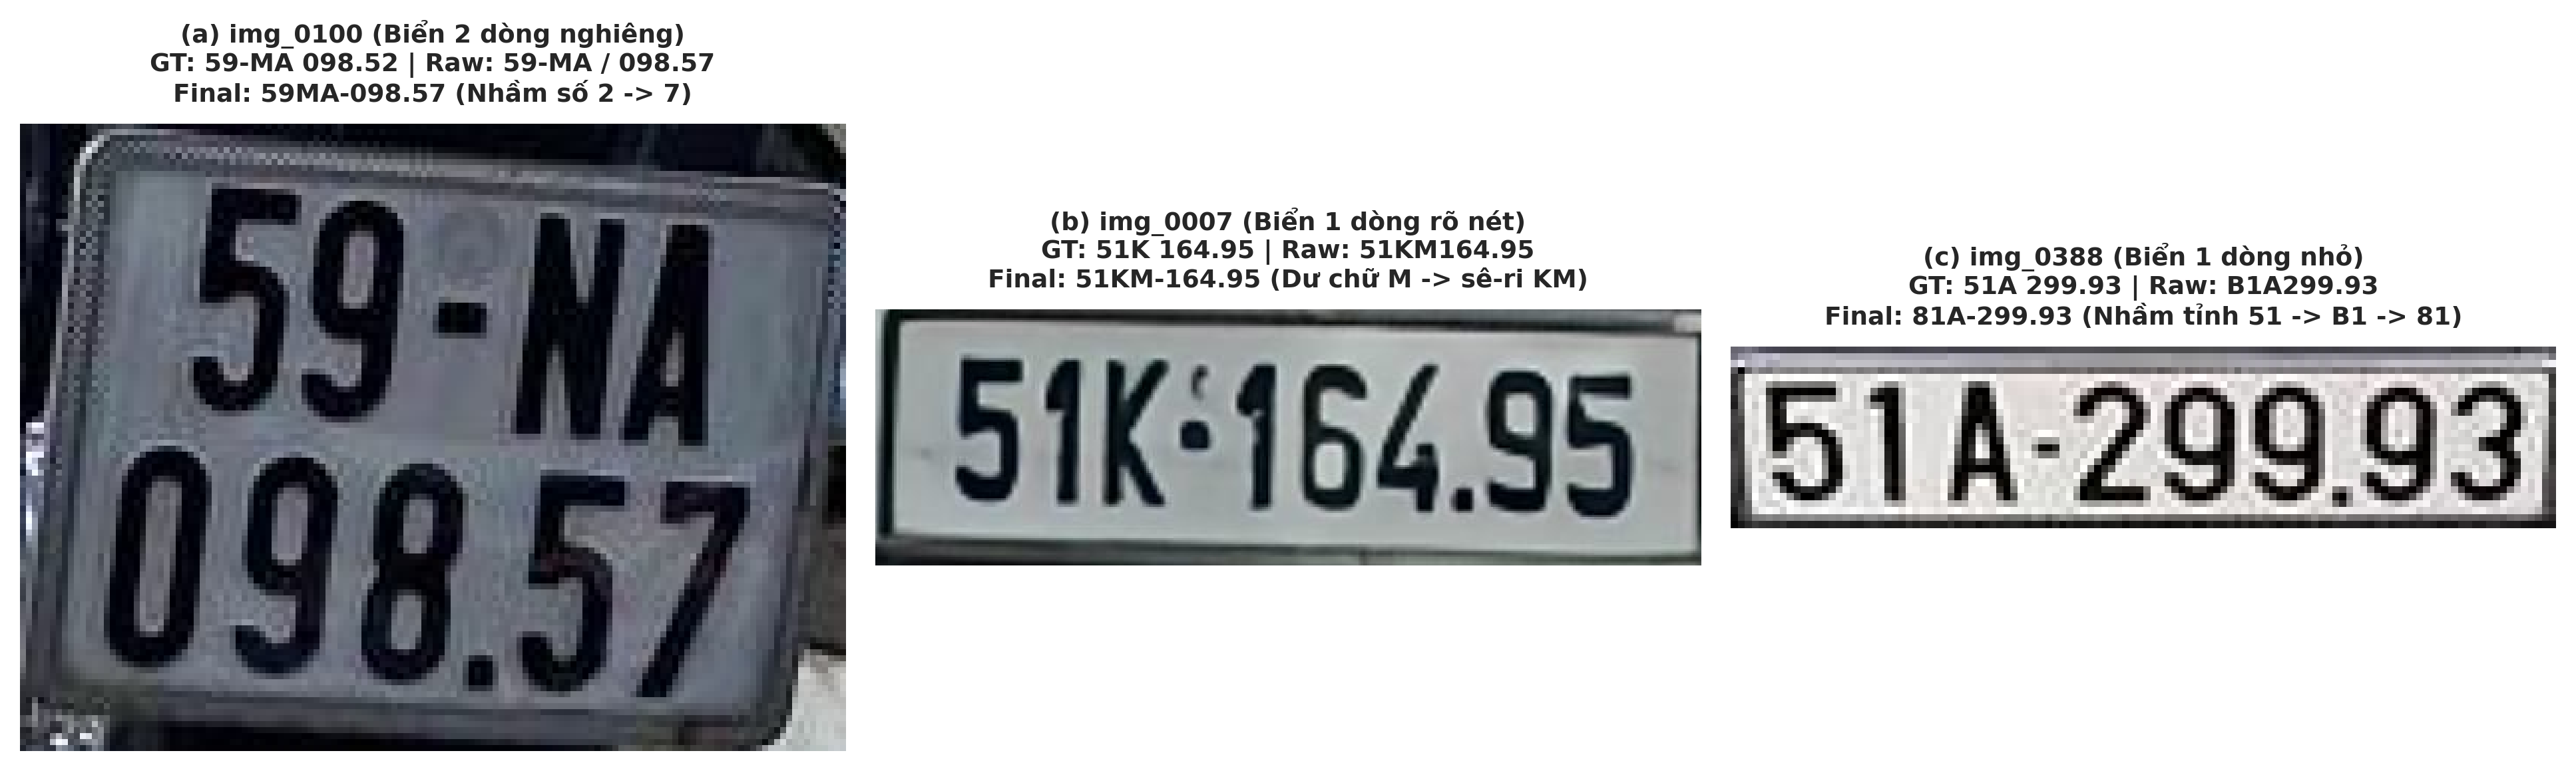

In [7]:
# Đặt cạnh nhau Ảnh crop, Ground Truth, Raw OCR, Final OCR và Lý do chấp nhận cho 3 ca False Accepts
from IPython.display import Image, display

df_false_accepts = pd.DataFrame([
    {
        "Mã mẫu": "img_0100",
        "Bố cục & Điều kiện": "2 dòng, Góc nghiêng",
        "Ground Truth": "59-MA 098.52",
        "Raw OCR": "59-MA / 098.57",
        "Final OCR (Chấp nhận)": "59MA-098.57",
        "Lý do chấp nhận & Bản chất lỗi": "Nhầm số '2' -> '7'. Chuỗi '59MA-098.57' vẫn khớp 100% Regex (Tỉnh 59 + Sê-ri 2 chữ MA + 5 số)."
    },
    {
        "Mã mẫu": "img_0007",
        "Bố cục & Điều kiện": "1 dòng, Rõ nét",
        "Ground Truth": "51K 164.95",
        "Raw OCR": "51KM164.95",
        "Final OCR (Chấp nhận)": "51KM-164.95",
        "Lý do chấp nhận & Bản chất lỗi": "Nhiễu ốc vít/viền làm dư chữ 'M'. Sê-ri 2 chữ cái 'KM' vẫn hợp lệ về mặt cú pháp Regex."
    },
    {
        "Mã mẫu": "img_0388",
        "Bố cục & Điều kiện": "1 dòng, Nhỏ",
        "Ground Truth": "51A 299.93",
        "Raw OCR": "B1A299.93",
        "Final OCR (Chấp nhận)": "81A-299.93",
        "Lý do chấp nhận & Bản chất lỗi": "Nhầm '5' -> 'B' rồi chuẩn hóa vị trí số thành '8', tạo ra mã tỉnh '81' hợp lệ cú pháp."
    }
])
display(df_false_accepts)

fig_fa_path = ADD_ROOT / "docs" / "figures_report" / "fig_8_5b_false_accepted_cases.png"
if fig_fa_path.exists():
    display(Image(filename=str(fig_fa_path)))